# Project 16: Ensemble Diversity Analysis

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Build an ensemble of models. Task: Measure model correlation; Remove redundant models; Evaluate ensemble performance change

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** An ensemble helps only if its members make different errors. This notebook measures that diversity, drops the most redundant member, and checks whether performance actually changes.

## Part 1 — Introduction

Diversity is measured as prediction disagreement / correlation on the same test set. No diversity claim is made beyond those measured values.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Individual models and diversity

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
df=df_full.sample(n=20000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
models={
 "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
 "DecisionTree": DecisionTreeClassifier(random_state=42),
 "RandomForest": RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1),
 "ExtraTrees": ExtraTreesClassifier(n_estimators=120, random_state=42, n_jobs=-1),
 "HistGB": HistGradientBoostingClassifier(random_state=42),
}
preds={}
for name,m in models.items():
    m.fit(Xtr,ytr); p=m.predict(Xte); preds[name]=p; print(name, "accuracy:", round(accuracy_score(yte,p),4), "macro-F1:", round(f1_score(yte,p,average="macro"),4))
pred_df=pd.DataFrame(preds)
corr=pred_df.corr()
print("Prediction correlation matrix (identical predictions = 1.0):\n", corr.round(3).to_string())
print("Mean pairwise correlation per model:\n", (corr.sum(axis=1)-1)/(len(corr)-1))

LogisticRegression accuracy: 0.7846 macro-F1: 0.7645


DecisionTree accuracy: 0.8476 macro-F1: 0.814


RandomForest accuracy: 0.8846 macro-F1: 0.8545


ExtraTrees accuracy: 0.852 macro-F1: 0.8216


HistGB accuracy: 0.8498 macro-F1: 0.8221
Prediction correlation matrix (identical predictions = 1.0):
                     LogisticRegression  DecisionTree  RandomForest  ExtraTrees  HistGB
LogisticRegression               1.000         0.884         0.924       0.922   0.926
DecisionTree                     0.884         1.000         0.931       0.907   0.917
RandomForest                     0.924         0.931         1.000       0.957   0.963
ExtraTrees                       0.922         0.907         0.957       1.000   0.940
HistGB                           0.926         0.917         0.963       0.940   1.000
Mean pairwise correlation per model:
 LogisticRegression    0.913805
DecisionTree          0.909847
RandomForest          0.943924
ExtraTrees            0.931317
HistGB                0.936408
dtype: float64


## Part 4 — Ensembles and redundant-member removal

Soft voting all models accuracy: 0.8784


Stacking accuracy: 0.8978
Most redundant model (highest mean prediction correlation): RandomForest 0.9439


Soft voting without RandomForest accuracy: 0.8764


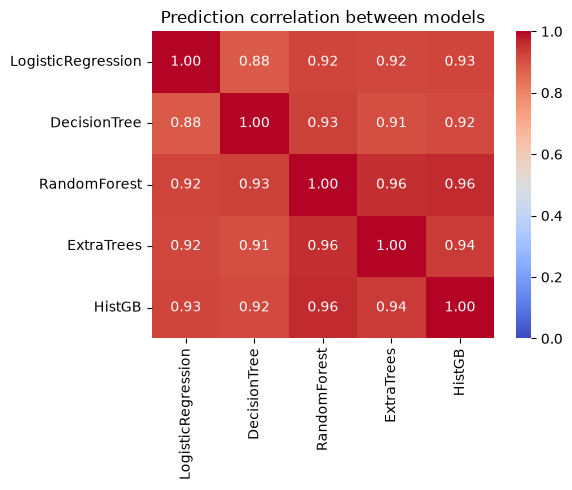

In [3]:
from sklearn.metrics import accuracy_score
# Soft voting needs probabilities: all models above support predict_proba except? Logistic, trees, RF, ET, HistGB all do.
voting=VotingClassifier(estimators=[(k,v) for k,v in models.items()], voting="soft"); voting.fit(Xtr,ytr); pv=voting.predict(Xte); print("Soft voting all models accuracy:", round(accuracy_score(yte,pv),4))
stack=StackingClassifier(estimators=[(k,v) for k,v in models.items()], final_estimator=LogisticRegression(max_iter=1000), cv=3, stack_method="predict_proba", passthrough=False); stack.fit(Xtr,ytr); print("Stacking accuracy:", round(accuracy_score(yte, stack.predict(Xte)),4))
# Most redundant = model with highest mean correlation with others
mean_corr=(corr.sum(axis=1)-1)/(len(corr)-1); redundant=mean_corr.idxmax(); print("Most redundant model (highest mean prediction correlation):", redundant, round(float(mean_corr.max()),4))
kept={k:v for k,v in models.items() if k!=redundant}
voting2=VotingClassifier(estimators=[(k,v) for k,v in kept.items()], voting="soft"); voting2.fit(Xtr,ytr); print(f"Soft voting without {redundant} accuracy:", round(accuracy_score(yte, voting2.predict(Xte)),4))
import seaborn as sns; plt.figure(figsize=(6,5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1); plt.title("Prediction correlation between models"); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: If dropping the most redundant model barely changes voting accuracy, that member added little diversity and can be removed to save compute. If accuracy falls, its errors were still useful despite correlation. The printed numbers decide which case held here.")

INTERPRETATION: If dropping the most redundant model barely changes voting accuracy, that member added little diversity and can be removed to save compute. If accuracy falls, its errors were still useful despite correlation. The printed numbers decide which case held here.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.